# 1. Channel Fingerprint Map Generation

## 0. Import

In [ ]:
import os

import numpy as np
import importlib
import matplotlib.pyplot as plt
import sionna.rt

from matplotlib.patches import Rectangle, Circle

from sionna.rt import (
    load_scene,
    Transmitter,
    Receiver,
    PlanarArray,
    PathSolver,
    InteractionType,
    subcarrier_frequencies,
)

print("Sionna RT version:", sionna.rt.__version__)

## 0. `project_config.py` 불러오기

In [ ]:
import project_config

importlib.reload(project_config)

from project_config import (
    ROOM_X,
    ROOM_Y,
    ROOM_Z,
    BS_CENTER,
    RX_HEIGHT,
    FREQ_HZ,
    BW_HZ,
    N_SC,
    DF_HZ,
    NF_DB,
    P_REF_DBM,
    NOISE_SC_DBM,
    GRID_RES,
    N_ROWS,
    N_COLS,
    CELL_X,
    CELL_Y,
    RX_POINTS,
    SCENE_XML,
    DATA_DIR,
    FINGERPRINT_PATH,
    AMR1_START_XY,
    AMR1_GOAL_XY,
    AMR2_START_XY,
    AMR2_GOAL_XY,
    MATERIALS,
    OBSTACLES,
)

print("Scene XML:", SCENE_XML)
print("BS:", BS_CENTER)
print("RX points:", RX_POINTS.shape)

## 0. `project_radio_material.py` 불러오기

In [ ]:
import project_radio_material

scene = load_scene(
    str(SCENE_XML),
    merge_shapes=False,
)

scene.frequency = FREQ_HZ
scene.bandwidth = BW_HZ

print("Scene load 성공")
print("Object 개수:", len(scene.objects))

## 1. subcarrier frequency 생성

In [ ]:
f = subcarrier_frequencies(
    num_subcarriers=N_SC,
    subcarrier_spacing=DF_HZ,
)

SC_OFFSETS_HZ = np.asarray(
    f.numpy() if hasattr(f, "numpy") else f,
    dtype=float,
)

SC_RF_HZ = FREQ_HZ + SC_OFFSETS_HZ

print("Subcarrier 개수:", len(SC_OFFSETS_HZ))
print("주파수 범위:", SC_RF_HZ[0], "~", SC_RF_HZ[-1])

## 2. Transmitter & Receiver 위치 설정

In [ ]:
# =========================================================
# antenna 설정
# =========================================================

scene.tx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V",
)

scene.rx_array = PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V",
)


# =========================================================
# BS에 transmitter 1개 추가
# =========================================================

scene.add(
    Transmitter(
        name="BS",
        position=BS_CENTER.tolist(),
    )
)


# =========================================================
# 720개 grid cell 각각에 receiver 추가
# =========================================================

for i, pos in enumerate(RX_POINTS):
    scene.add(
        Receiver(
            name=f"rx{i:03d}",
            position=pos.tolist(),
        )
    )

print("BS 1개 추가 완료:", BS_CENTER)
print("Receiver 추가 완료:", len(RX_POINTS))

## 3. PathSolver로 전파 경로 탐색

In [ ]:
solver = PathSolver()
paths = solver(
    scene=scene,
    max_depth=5,   # reflection과 penetration이 모두 포함됨
    synthetic_array=True,
    los=True,
    specular_reflection=True,   # 정반사
    diffuse_reflection=False,   # 확산반사
    refraction=True,            # 투과 (penetration)
    diffraction=False,
    edge_diffraction=False,
)

print("PathSolver finished")

valid_rt = np.asarray(paths.valid.numpy(),dtype=bool,)
paths_per_receiver = np.sum(valid_rt,axis=-1,)
print("paths found:", int(np.sum(valid_rt)))

In [ ]:
# ---------------------------------------
# (LOS 1개 + 외벽 반사 1개)를 만족하는 path만 남기기
# ---------------------------------------

valid_rt = np.asarray(paths.valid.numpy(), dtype=bool)
interactions_rt = np.asarray(paths.interactions.numpy())

SPECULAR_T = int(InteractionType.SPECULAR)

# 경로마다 외벽 반사 횟수 계산
# 내부 장애물 투과(REFRACTION)는 세지 않음
n_wall_reflections = np.sum(
    interactions_rt == SPECULAR_T,
    axis=0,
)

# 외벽 반사가 0회 또는 1회인 경로만 유지
# 0회: LOS(중간에 내부 장애물 투과 가능)
# 1회: 외벽 1차 반사경로(중간에 내부 장애물 투과 가능)
keep_paths = (
    valid_rt
    & (n_wall_reflections <= 1)
)

filtered_path_count = np.sum(
    keep_paths,
    axis=-1,
)

print(
    "남은 전체 경로 수:",
    int(np.sum(filtered_path_count)),
)

## 4. CFR(Channel Frequency Response) 계산

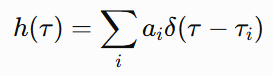

In [ ]:
# =========================================================
# Sionna가 계산한 경로별 CIR 가져오기() + filtering하기
# =========================================================

a_paths, tau_paths = paths.cir(
    normalize_delays=False,
    num_time_steps=1,
    out_type="numpy",
)

a_paths = np.asarray(a_paths)        # complex path coefficient
tau_paths = np.asarray(tau_paths)    # time delay


# tau_paths와 keep_paths는 모두 [receiver, transmitter, path]
if tau_paths.shape != keep_paths.shape:
    raise ValueError(
        f"tau와 path mask shape이 다릅니다: "
        f"{tau_paths.shape} vs {keep_paths.shape}"
    )


# keep_paths를 a_paths의 shape에 맞게 확장하고,
# 제외할 경로의 복소 채널 계수를 0으로 설정
path_mask = keep_paths[:, None, :, None, :, None]
a_filtered = a_paths * path_mask

In [ ]:
# =========================================================
# 필터링된 경로(a_filtered)를 이용한 64-subcarrier CFR 계산
# =========================================================

# delay를 CFR 계산 차원에 맞게 확장
tau_expanded = tau_paths[:, None, :, None, :, None]

# path별, subcarrier별 delay의 phase
path_phase = np.exp(-1j* 2.0* np.pi* tau_expanded* SC_OFFSETS_HZ[None, None, None, None, None, :])

# 각 path가 각 subcarrier에 기여하는 복소 채널
path_cfr = a_filtered * path_phase

# path를 복소수로 합산 (LOS + 서쪽 반사 + 동쪽 반사 + 남쪽 반사 + 북쪽 반사)
H_links = np.sum(path_cfr, axis=4)


# 크기가 1인 SISO 차원 제거
H_flat = H_links[:, 0, 0, 0, :]

# 720개 receiver를 20×36 grid로 복원
H = H_flat.reshape(N_ROWS,N_COLS,N_SC,)

print("Fingerprint H shape (세로, 가로, subcarrier 수):", H.shape)

In [ ]:
# =========================================================
# Per-subcarrier SNR 및 평균 SNR
# =========================================================

# Watt 단위로 환산
p_ref_w = 10.0 ** ((P_REF_DBM - 30.0) / 10.0)
noise_sc_w = 10.0 ** ((NOISE_SC_DBM - 30.0) / 10.0)

# 부반송파별 SNR
snr_sc_linear = (
    p_ref_w
    * np.abs(H)**2
    / noise_sc_w
)

# 64개 부반송파 평균
snr_linear = np.mean(
    snr_sc_linear,
    axis=2,
)

# SNR을 dB 단위로 변환
snr_db = 10.0 * np.log10(
    np.maximum(snr_linear, 1e-30)
)

print("Per-subcarrier SNR shape:", snr_sc_linear.shape)
print("Average SNR map shape   :", snr_db.shape)
print("SNR 범위:", snr_db.min(), "~", snr_db.max(), "dB")


# =========================================================
# Fingerprint 저장
# =========================================================

DATA_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    FINGERPRINT_PATH,
    H=H,
    snr_db=snr_db,
    snr_sc_linear=snr_sc_linear,
    cell_x=CELL_X,
    cell_y=CELL_Y,
    sc_rf_hz=SC_RF_HZ,
    grid_res=GRID_RES,
    room_x=ROOM_X,
    room_y=ROOM_Y,
)

print("저장 완료:", FINGERPRINT_PATH)

## 5. SNR map 검증 및 분석

In [ ]:
# =========================================================
# 기준 위치 SNR 확인
# =========================================================

# (x, y)에서 가장 가까운 격자 셀을 찾는 함수
def cell_of(x, y):
    c = int(np.argmin(np.abs(CELL_X - x)))
    r = int(np.argmin(np.abs(CELL_Y - y)))
    return r, c

for (x, y), tgt in [((3.0, 3.0), "≈ 50 dB"), ((13.0, 5.0), "≲ 25 dB")]:
    r, c = cell_of(x, y)
    print(f"({x:4.1f},{y:4.1f}) -> cell({CELL_X[c]:5.2f},{CELL_Y[r]:5.2f})  "
          f"SNR = {snr_db[r, c]:6.2f} dB   (target {tgt})")

In [ ]:
# =========================================================
# 전체 SNR map의 최대·최소
# =========================================================

# snr_db에서 가장 큰 값을 갖는 cell 찾기
r_hi, c_hi = np.unravel_index(np.argmax(snr_db), snr_db.shape)

# snr db에서 가장 작은 값을 갖는 cell 찾기
r_lo, c_lo = np.unravel_index(np.argmin(snr_db), snr_db.shape)

print(f"brightest ({CELL_X[c_hi]:5.2f},{CELL_Y[r_hi]:5.2f})       : {snr_db[r_hi,c_hi]:6.2f} dB")
print(f"darkest   ({CELL_X[c_lo]:5.2f},{CELL_Y[r_lo]:5.2f})       : {snr_db[r_lo,c_lo]:6.2f} dB")
print(f"contrast (최대 SNR - 최소 SNR)  : {snr_db[r_hi,c_hi] - snr_db[r_lo,c_lo]:6.2f} dB")

In [ ]:
# =========================================================
# AMR1 경로상의 SNR 구해보기
# =========================================================

# AMR1이 이동하는 경로상에서의 격자 중심 찾기
def snr_bilinear(x, y):
    fx = (np.asarray(x, dtype=float) - CELL_X[0]) / GRID_RES
    fy = (np.asarray(y, dtype=float) - CELL_Y[0]) / GRID_RES
    i = np.clip(np.floor(fx).astype(int), 0, N_COLS - 2)
    j = np.clip(np.floor(fy).astype(int), 0, N_ROWS - 2)
    a = np.clip(fx - i, 0.0, 1.0)
    b = np.clip(fy - j, 0.0, 1.0)
    return ((1-a)*(1-b)*snr_db[j, i]   + a*(1-b)*snr_db[j, i+1]
          + (1-a)*b   *snr_db[j+1, i]  + a*b    *snr_db[j+1, i+1])

# AMR1의 이동 경로 (그냥 아무런 세 포인트로 경로 정한거임)
wp  = np.array([[1., 2.], [9., 5.25], [17., 8.]])

# 선분의 길이 계산 & 전체 경로의 길이 계산
seg = np.linalg.norm(np.diff(wp, axis=0), axis=1)
L   = seg.sum()

print(f"AMR1 근사경로 길이 {L:.2f} m")
for s in np.linspace(0, L, 6):
    if s <= seg[0]:
        p = wp[0] + (s / seg[0]) * (wp[1] - wp[0])
    else:
        p = wp[1] + ((s - seg[0]) / seg[1]) * (wp[2] - wp[1])
    print(f"  s={s:5.2f} m  ({p[0]:5.2f},{p[1]:5.2f})  SNR = {snr_bilinear(*p):6.2f} dB")

## 6. Heatmap 생성

In [ ]:
# AMR 시작점과 도착점
AMR1_START = tuple(AMR1_START_XY)
AMR1_GOAL = tuple(AMR1_GOAL_XY)
AMR2_START = tuple(AMR2_START_XY)
AMR2_GOAL = tuple(AMR2_GOAL_XY)

fig, ax = plt.subplots(figsize=(12, 6.5))

# ---------------------------------------
# 1. SNR heat map
# ---------------------------------------
im = ax.imshow(
    snr_db, origin="lower",
    extent=[CELL_X[0] - GRID_RES/2, CELL_X[-1] + GRID_RES/2,
            CELL_Y[0] - GRID_RES/2, CELL_Y[-1] + GRID_RES/2],
    cmap="viridis", aspect="equal", zorder=0,
)

# ---------------------------------------
# 2. 외벽
# ---------------------------------------
ax.add_patch(Rectangle((0, 0), ROOM_X, ROOM_Y, fill=False, edgecolor="black",
                       linewidth=3, zorder=4, label="Perimeter wall"))

# ---------------------------------------
# 3. 내부 장애물
# ---------------------------------------
concrete_label_used = False
wood_label_used = False

for ob in OBSTACLES:
    if ob["material"] == "wood":
        color = "#c8963c"
        label = None if wood_label_used else "Wood obstacle"
        wood_label_used = True
    else:
        color = "#b0b0b0"
        label = None if concrete_label_used else "Concrete obstacle"
        concrete_label_used = True

    # 중앙벽 또는 캐비닛
    if ob["kind"] == "box":
        dx, dy, _ = ob["size"]
        x, y = ob["center"]
        ax.add_patch(Rectangle((x - dx/2, y - dy/2), dx, dy, facecolor=color,
                               edgecolor="black", linewidth=1.2, alpha=0.65,
                               zorder=3, label=label))
    # 원기둥
    else:
        x, y = ob["center"]
        ax.add_patch(Circle((x, y), ob["radius"], facecolor=color,
                            edgecolor="black", linewidth=1.2, alpha=0.65,
                            zorder=3, label=label))

    # 장애물 이름
    ax.annotate(ob["name"], ob["center"], fontsize=9, color="black",
                ha="center", va="center", zorder=5,
                bbox=dict(boxstyle="round,pad=0.1", facecolor="white",
                          edgecolor="none", alpha=0.6))

# ---------------------------------------
# 4. BS 위치
# ---------------------------------------
ax.scatter(BS_CENTER[0], BS_CENTER[1], marker="*", s=300, color="red",
           edgecolor="black", linewidth=1.0, zorder=7, label="BS")
ax.annotate("BS", BS_CENTER[:2], xytext=(3.0, 5.55), fontsize=13,
            fontweight="bold", color="red", ha="center", zorder=7)

# ---------------------------------------
# 5. AMR1 시작점과 도착점
# ---------------------------------------
ax.scatter(*AMR1_START, marker="s", s=120, color="royalblue",
           edgecolor="black", zorder=7, label="AMR1 start")
ax.scatter(*AMR1_GOAL, marker="^", s=150, color="royalblue",
           edgecolor="black", zorder=7, label="AMR1 goal")
ax.annotate("AMR1 S", AMR1_START, xytext=(1.0, 2.35), ha="center", fontsize=12,
            color="royalblue", fontweight="bold", zorder=7)
ax.annotate("AMR1 G", AMR1_GOAL, xytext=(17.0, 8.35), ha="center", fontsize=12,
            color="royalblue", fontweight="bold", zorder=7)

# ---------------------------------------
# 6. AMR2 시작점과 도착점
# ---------------------------------------
ax.scatter(*AMR2_START, marker="s", s=120, color="darkorange",
           edgecolor="black", zorder=7, label="AMR2 start")
ax.scatter(*AMR2_GOAL, marker="^", s=150, color="darkorange",
           edgecolor="black", zorder=7, label="AMR2 goal")
ax.annotate("AMR2 S", AMR2_START, xytext=(17.0, 2.35), ha="center", fontsize=12,
            color="darkorange", fontweight="bold", zorder=7)
ax.annotate("AMR2 G", AMR2_GOAL, xytext=(1.0, 8.35), ha="center", fontsize=12,
            color="darkorange", fontweight="bold", zorder=7)

# ---------------------------------------
# 7. 그래프 설정
# ---------------------------------------
ax.set_xlim(0, ROOM_X)
ax.set_ylim(0, ROOM_Y)

# 축 제목
ax.set_xlabel(
    "x [m]",
    fontsize=15,
    labelpad=8,
)

ax.set_ylabel(
    "y [m]",
    fontsize=15,
    labelpad=8,
)

# 그래프 제목
ax.set_title(
    "SNR Heatmap",
    fontsize=20,
    pad=12,
)

# 축 눈금 숫자
ax.tick_params(
    axis="both",
    labelsize=13,
)

ax.set_aspect("equal")


# Colorbar
cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.035,
    pad=0.03,
)

cbar.set_label(
    "SNR [dB]",
    fontsize=15,
    labelpad=10,
)

cbar.ax.tick_params(
    labelsize=13,
)


# 범례
ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.11),
    ncol=4,
    fontsize=11,        # 기존 8
    framealpha=0.95,
)

fig.tight_layout()
plt.show()

## 7. AMR 두 개를 receiver로 path 계산

In [ ]:
# ---------------------------
# AMR 출발점의 위치를 receiver로 잡아서 별도로 path solve
# (720개 격자점용 scene은 건드리지 않고, 새 scene을 하나 더 만들어 사용)
# ---------------------------
AMR1_START = tuple(AMR1_START_XY)
AMR2_START = tuple(AMR2_START_XY)

AMR_POINTS = {
    "AMR1": (AMR1_START[0], AMR1_START[1], RX_HEIGHT),
    "AMR2": (AMR2_START[0], AMR2_START[1], RX_HEIGHT),
}

scene_amr = load_scene(str(SCENE_XML), merge_shapes=False)
scene_amr.frequency = FREQ_HZ
scene_amr.bandwidth = BW_HZ

scene_amr.tx_array = PlanarArray(
    num_rows=1, num_cols=1,
    vertical_spacing=0.5, horizontal_spacing=0.5,
    pattern="iso", polarization="V",
)
scene_amr.rx_array = PlanarArray(
    num_rows=1, num_cols=1,
    vertical_spacing=0.5, horizontal_spacing=0.5,
    pattern="iso", polarization="V",
)

scene_amr.add(Transmitter(name="BS", position=BS_CENTER.tolist()))

amr_names = list(AMR_POINTS.keys())
for name, pos in AMR_POINTS.items():
    scene_amr.add(Receiver(name=name, position=list(pos)))

solver_amr = PathSolver()
paths_amr = solver_amr(
    scene=scene_amr,
    max_depth=5,
    synthetic_array=True,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    refraction=True,
    diffraction=False,
    edge_diffraction=False,
)

print("PathSolver finished")

valid_amr = np.asarray(paths_amr.valid.numpy())               # [rx, rx_ant, tx, tx_ant, path]
vertices_amr = np.asarray(paths_amr.vertices.numpy())         # [depth, rx, rx_ant, tx, tx_ant, path, 3]
interactions_amr = np.asarray(paths_amr.interactions.numpy()) # [depth, rx, rx_ant, tx, tx_ant, path]
sources_amr = np.asarray(paths_amr.sources.numpy()).T           # BS 위치, shape (num_tx, 3)
targets_amr = np.asarray(paths_amr.targets.numpy()).T           # AMR 위치, shape (num_rx, 3)

for i, name in enumerate(amr_names):
    n_valid = int(valid_amr[i, 0, :].sum())   # <- [i, 0, 0, 0, :] 대신 [i, 0, :]
    print(f"{name}: 유효 경로 {n_valid}개")

In [ ]:
# ---------------------------------------
# AMR1, AMR2 경로 필터링
# 외벽 반사 0~1회 경로만 유지
# ---------------------------------------

valid_amr_rt = np.asarray(
    paths_amr.valid.numpy(),
    dtype=bool,
)

interactions_amr_rt = np.asarray(
    paths_amr.interactions.numpy()
)

SPECULAR_T = int(InteractionType.SPECULAR)

print("valid_amr_rt shape       :", valid_amr_rt.shape)
print("interactions_amr_rt shape:", interactions_amr_rt.shape)


# AMR 경로마다 외벽 반사 횟수 계산
# 내부 장애물 투과(REFRACTION)는 세지 않음
n_wall_reflections_amr = np.sum(
    interactions_amr_rt == SPECULAR_T,
    axis=0,
)

# 외벽 반사 2회 이상 제거
keep_amr_paths = (
    valid_amr_rt
    & (n_wall_reflections_amr < 2)
)

# AMR별 필터링 전후 경로 수
original_amr_paths = np.sum(
    valid_amr_rt,
    axis=-1,
).reshape(-1)

filtered_amr_paths = np.sum(
    keep_amr_paths,
    axis=-1,
).reshape(-1)


amr_names = ["AMR1", "AMR2"]

print("\n[AMR 경로 필터링 결과]")

for i, name in enumerate(amr_names):
    removed = (
        original_amr_paths[i]
        - filtered_amr_paths[i]
    )

    print(
        f"{name}: "
        f"필터링 전 {original_amr_paths[i]}개 → "
        f"필터링 후 {filtered_amr_paths[i]}개 "
    )

In [ ]:
# ---------------------------------------
# AMR별로 찾은 경로를 방 위에 선으로 시각화
# ---------------------------------------
plt.rcParams["font.family"] = "DejaVu Sans"      # 윈도우 기본 내장 한글 폰트
plt.rcParams['axes.unicode_minus'] = False       # 마이너스 부호(-) 깨짐 방지 (한글폰트 쓸 때 같이 필요)

NONE_T = int(InteractionType.NONE)
SPECULAR_T = int(InteractionType.SPECULAR)
REFRACTION_T = int(InteractionType.REFRACTION)

def path_xy_chain(r_idx, p_idx):
    """receiver r_idx, path p_idx 의 (x,y) 꼭짓점을 BS→...→AMR 순서로 반환."""
    chain = [sources_amr[0, :2]]  # BS (tx는 1개뿐이라 index 0)
    for d in range(vertices_amr.shape[0]):  # max_depth
        if interactions_amr[d, r_idx, 0, p_idx] == NONE_T:
            break  # 이후 슬롯은 다 미사용 (앞에서부터 꽉 채워지는 구조)
        chain.append(vertices_amr[d, r_idx, 0, p_idx, :2])
    chain.append(targets_amr[r_idx, :2])
    return np.array(chain)

def classify_path(r_idx, p_idx):
    types = set()
    for d in range(interactions_amr.shape[0]):
        t = int(interactions_amr[d, r_idx, 0, p_idx])
        if t != NONE_T:
            types.add(t)
    if not types:
        return "LOS"
    if types == {SPECULAR_T}:
        return "reflect"
    if types == {REFRACTION_T}:
        return "transmit"
    return "mixed"

STYLE = {
    "LOS":      dict(color="crimson",    linestyle="-",  linewidth=2.0, label="LOS"),
    "reflect":  dict(color="royalblue",  linestyle="--", linewidth=1.3, label="reflection"),
    "transmit": dict(color="seagreen",   linestyle=":",  linewidth=1.3, label="refraction"),
    "mixed":    dict(color="darkorange", linestyle="-.", linewidth=1.3, label="reflection+refraction"),
}

fig, axes = plt.subplots(len(amr_names), figsize=(11, 11), sharex=True, sharey=True)
if len(amr_names) == 1:
    axes = [axes]

for ax, name in zip(axes, amr_names):
    r_idx = amr_names.index(name)

    ax.add_patch(Rectangle((0, 0), ROOM_X, ROOM_Y, fill=False,
                            edgecolor="black", linewidth=2, zorder=4))
    for ob in OBSTACLES:
        color = "#c8963c" if ob["material"] == "wood" else "#b0b0b0"
        if ob["kind"] == "box":
            dx, dy, _ = ob["size"]
            x, y = ob["center"]
            ax.add_patch(Rectangle((x - dx/2, y - dy/2), dx, dy,
                                    facecolor=color, edgecolor="black",
                                    linewidth=0.8, alpha=0.5, zorder=2))
        else:
            x, y = ob["center"]
            ax.add_patch(Circle((x, y), ob["radius"], facecolor=color,
                                 edgecolor="black", linewidth=0.8, alpha=0.5, zorder=2))

    ax.scatter(*BS_CENTER[:2], marker="*", s=250, color="red",
               edgecolor="black", zorder=6, label="BS")
    ax.scatter(*targets_amr[r_idx, :2], marker="s", s=100, color="black",
               zorder=6, label=name)

    used_labels = set()
    n_valid = int(keep_amr_paths[r_idx, 0, :].sum())

    for p_idx in range(keep_amr_paths.shape[-1]):
        if not keep_amr_paths[r_idx, 0, p_idx]:
            continue

        kind = classify_path(r_idx, p_idx)
        chain = path_xy_chain(r_idx, p_idx)
        style = dict(STYLE[kind])
        if kind in used_labels:
            style["label"] = None
        used_labels.add(kind)
        ax.plot(chain[:, 0], chain[:, 1], zorder=5, **style)

    ax.set_title(f"{name} — number of valid path: {n_valid}", fontsize=18,)
    ax.set_xlim(0, ROOM_X)
    ax.set_ylim(0, ROOM_Y)
    ax.set_aspect("equal")
    ax.set_xlabel("x [m]", fontsize=15)
    ax.legend(loc="upper right", fontsize=12, framealpha=0.9)

axes[0].set_ylabel("y [m]")
fig.suptitle("BS → AMR path", fontsize=18)
fig.tight_layout()
plt.show()